# Líneas base y candidatos

| | |
|---|---|
| **Entrega** | PSet 3, secciones 5 (línea base) y 6 (candidatos) de `CD_PSet_3.pdf` |
| **Autor** | Allan Paul Gómez Ehmig (00351916) |
| **Datos** | solo **entrenamiento**; todo se mide en los 84 meses fuera de muestra de los pliegues (2017–2023) |
| **MLflow** | experimento `portafolio-inversiones` (levantar con los comandos del README, sin Kestra ni Spark) |

**Sección 5 del PDF.** Antes de entrenar cualquier modelo, entrena dos líneas base:
1. **Ingenua:** `DummyRegressor` o `DummyClassifier` (media, mediana o clase más frecuente).
2. **De negocio:** la regla o el proceso actual definido en el PSet #1 (si existe).

Todo modelo candidato tiene que superar a las dos. Si alguno no lo logra, se documenta como hallazgo.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.datos import cargar
from src.pipeline import preparar, dividir, FEATURES, TARGET, pliegues
from src.negocio import RiesgoDiario, REGLA, portafolios_aleatorios, portafolio_universo, serie_indice, resumen, backtest
from src.entorno import SEMILLA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
obt, metadata = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)
train = train.reset_index(drop=True)
dia, metadata_dia = cargar(grano='dia')           # covarianzas para el tope de portafolio
riesgo = RiesgoDiario(dia)
print({'fuente': metadata['tabla'], 'sha256': metadata['sha256'], 'filas_obt': len(obt), 'entrenamiento': len(train),
       'holdout_reservado': len(holdout), 'sha256_dia': metadata_dia['sha256'][:16]})

{'fuente': 'PORTAFOLIO_P3.OBT.OBT_ACCION_MES', 'sha256': 'c356891723976bceaa7447fe9682902ea520e46ad5bc9490ba43093a228f228f', 'filas_obt': 87178, 'entrenamiento': 46851, 'holdout_reservado': 11326, 'sha256_dia': 'a5e12dfad32f5df7'}


## 5. Líneas base

Las líneas base se miden con las dos métricas del proyecto (notebook `03_preparacion_validacion`):
- **Técnica:** el MAE en la validación cruzada.
- **De negocio:** el Sharpe neto y el drawdown del portafolio.

| Clave | Línea base | Qué mide | Familia (tag) |
|---|---|---|---|
| **B1** | `DummyRegressor` con la media del entrenamiento | **ingenua del PDF**: piso de la métrica técnica | `linea_base` |
| B2 | Random walk: retorno 0 (`DummyRegressor` constante) | piso del PSet 1 para la métrica técnica | `linea_base` |
| **B5** | Universo **S&P 500 ∩ NYSE** con igual ponderación | **de negocio**: invertir en todo el universo sin elegir | N/A |
| B4 | Portafolios al azar con la regla del PSet 1 | si el modelo elige mejor que el azar | N/A |
| B6 | S&P 500 y NYSE Composite (índices) | la alternativa pasiva del cliente, como contexto | N/A |

**Por qué la línea base de negocio es el universo común (B5) y no el índice.** El análisis solo usa acciones que
están en el S&P 500 **y** cotizan en la NYSE. Hay dos razones por las que un índice no es comparable:
- **El universo:** el S&P 500 incluye acciones de NASDAQ que nunca podemos elegir, y el NYSE Composite incluye
  miles de acciones fuera del S&P 500.
- **Los dividendos:** ^GSPC y ^NYA son índices de **precio**, sin dividendos, mientras que los retornos de las
  acciones están ajustados y los incluyen. Eso pone al índice en desventaja de ~1,5–2 % al año.

B5 compra todas las acciones elegibles de cada mes con igual ponderación y paga el mismo costo de 15 pb: es "el
índice de nuestro universo", la referencia justa. B4 (el azar) y los dos índices quedan como contexto.

Las líneas base de negocio no tienen modelo: en MLflow van con `familia = N/A` y una descripción corta en
`modelo`.

In [2]:
# B1 y B2 en MLflow con el mismo registro que tendran los candidatos (src/experimentos.py).
from src.experimentos import evaluar_candidatos, registrar_referencia
REGISTRAR = True          # False para revisar el notebook sin crear corridas nuevas en MLflow
if REGISTRAR:
    base_tecnica = evaluar_candidatos(train, metadata, riesgo, metadata_dia, nombres=['B1_media', 'B2_rw_cero'])
    display(base_tecnica[['modelo', 'familia', 'fase', 'run_id', 'mae_cv_media', 'mae_cv_std', 'mae_train_cv',
                          'brecha_mae', 'rmse_cv_media', 'segundos_entrenamiento', 'git_dirty']].round(5))

/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/11/18 11:37:44 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run B1_media at: http://localhost:5001/#/experiments/2/runs/b451f63a58694c23b6bc239fa866a5ba
🧪 View experiment at: http://localhost:5001/#/experiments/2


/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/src/pipeline.py:288: RuntimeWarning: Mean of empty slice
  salida.update({f'{nombre}_cv_media': float(np.nanmean(cv)), f'{nombre}_cv_std': float(np.nanstd(cv, ddof=1)),
/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/src/pipeline.py:289: RuntimeWarning: Mean of empty slice
  f'{nombre}_train_cv': float(np.nanmean(ent))})


/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/11/18 11:37:48 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run B2_rw_cero at: http://localhost:5001/#/experiments/2/runs/9852014c9b5d4fe3a52c6bf4af80b146
🧪 View experiment at: http://localhost:5001/#/experiments/2


,modelo,familia,fase,run_id,mae_cv_media,mae_cv_std,mae_train_cv,brecha_mae,rmse_cv_media,segundos_entrenamiento,git_dirty
0,B1_media,linea_base,baseline,b451f63a58694c23b6bc239fa866a5ba,0.06410,0.01649,0.05290,0.01120,0.08675,0.80979,False
1,B2_rw_cero,linea_base,baseline,9852014c9b5d4fe3a52c6bf4af80b146,0.06474,0.01593,0.05392,0.01082,0.08702,0.71278,False


In [3]:
# Referencias de negocio en los mismos 84 meses de validacion de los pliegues (sin hold-out).
cv = pliegues(train)
val = train.iloc[np.concatenate([iv for _, iv in cv])]
meses = sorted(val.anio_mes.unique())
print(f'{len(meses)} meses de validacion: decisiones {meses[0]}..{meses[-1]}, filas {len(val)}')

series = {
    'B5 universo S&P 500 ∩ NYSE, igual ponderación': portafolio_universo(val),
    'B6 S&P 500 (índice de precio)': serie_indice(val, 'ret_log_sp500_mes_siguiente'),
    'B6 NYSE Composite (índice de precio)': serie_indice(val, 'ret_log_nyse_composite_mes_siguiente'),
}
aleatorios = portafolios_aleatorios(val, sorteos=200, semilla=SEMILLA, riesgo=riesgo, **REGLA)
mediano = int((aleatorios.sharpe_neto - aleatorios.sharpe_neto.median()).abs().idxmin())
rng = np.random.default_rng(SEMILLA)                      # se reproduce el sorteo mediano para su serie
for s in range(mediano + 1):
    azar = rng.random(len(val))
series['B4 azar con la regla del PSet 1 (sorteo mediano de 200)'] = backtest(val.assign(_azar=azar), '_azar', riesgo=riesgo, **REGLA)

tabla = pd.DataFrame({n: {**resumen(s), 'invertido_prom': s['invertido'].mean(), 'acciones_prom': s['n_acciones'].mean()}
                      for n, s in series.items()}).T
display(tabla[['sharpe_neto', 'drawdown_max', 'retorno_anual_neto', 'turnover_prom', 'invertido_prom', 'acciones_prom']]
        .astype(float).round(3))
print(f"B4, 200 sorteos: Sharpe neto mediana {aleatorios.sharpe_neto.median():.3f}, p10 {aleatorios.sharpe_neto.quantile(.1):.3f}, "
      f"p90 {aleatorios.sharpe_neto.quantile(.9):.3f}; drawdown mediana {aleatorios.drawdown_max.median():.3f}")

84 meses de validacion: decisiones 201612..202311, filas 26696


,sharpe_neto,drawdown_max,retorno_anual_neto,turnover_prom,invertido_prom,acciones_prom
"B5 universo S&P 500 ∩ NYSE, igual ponderación",0.544,-0.293,0.107,0.066,1.0,317.81
B6 S&P 500 (índice de precio),0.626,-0.248,0.114,0.000,1.0,NaN
B6 NYSE Composite (índice de precio),0.342,-0.260,0.062,0.000,1.0,NaN
B4 azar con la regla del PSet 1 (sorteo mediano de 200),0.345,-0.289,0.064,1.916,1.0,10.00


B4, 200 sorteos: Sharpe neto mediana 0.344, p10 0.176, p90 0.529; drawdown mediana -0.270


In [4]:
# Registro de las referencias de negocio en MLflow: familia "N/A" y una descripcion corta en "modelo".
cortos = {'B5 universo S&P 500 ∩ NYSE, igual ponderación': 'Universo S&P500∩NYSE igual ponderación',
          'B6 S&P 500 (índice de precio)': 'Índice S&P 500 (precio)',
          'B6 NYSE Composite (índice de precio)': 'Índice NYSE Composite (precio)',
          'B4 azar con la regla del PSet 1 (sorteo mediano de 200)': 'Portafolio al azar, regla PSet 1'}
if REGISTRAR:
    filas = []
    for nombre, serie in series.items():
        extra = {'costo_bps': str(REGLA['costo_bps'])}
        if nombre.startswith('B4'):
            extra.update({f'regla_{k}': str(v) for k, v in REGLA.items()})
            extra.update({'sorteos': '200', 'sorteo_reportado': f'mediano ({mediano})',
                          'sharpe_p10': f'{aleatorios.sharpe_neto.quantile(.1):.4f}', 'sharpe_p90': f'{aleatorios.sharpe_neto.quantile(.9):.4f}'})
        filas.append(registrar_referencia(cortos[nombre], serie, metadata, parametros=extra, meta_dia=metadata_dia))
    display(pd.DataFrame(filas)[['modelo', 'familia', 'fase', 'run_id', 'negocio_sharpe_neto', 'negocio_drawdown_max', 'git_dirty']].round(3))

🏃 View run Universo S&P500∩NYSE igual ponderación at: http://localhost:5001/#/experiments/2/runs/8caa002732304ae1859e71e93e78ff6e
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run Índice S&P 500 (precio) at: http://localhost:5001/#/experiments/2/runs/33abac827ad24521bc19e68dabaed68e
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run Índice NYSE Composite (precio) at: http://localhost:5001/#/experiments/2/runs/2928c3fde3e540a3b8fba770ff70d1e4
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run Portafolio al azar, regla PSet 1 at: http://localhost:5001/#/experiments/2/runs/5c85db15645a4df09c3e54874d96123a
🧪 View experiment at: http://localhost:5001/#/experiments/2


,modelo,familia,fase,run_id,negocio_sharpe_neto,negocio_drawdown_max,git_dirty
0,Universo S&P500∩NYSE igual ponderación,N/A,baseline,8caa002732304ae1859e71e93e78ff6e,0.544,-0.293,True
1,Índice S&P 500 (precio),N/A,baseline,33abac827ad24521bc19e68dabaed68e,0.626,-0.248,True
2,Índice NYSE Composite (precio),N/A,baseline,2928c3fde3e540a3b8fba770ff70d1e4,0.342,-0.260,True
3,"Portafolio al azar, regla PSet 1",N/A,baseline,5c85db15645a4df09c3e54874d96123a,0.345,-0.289,True


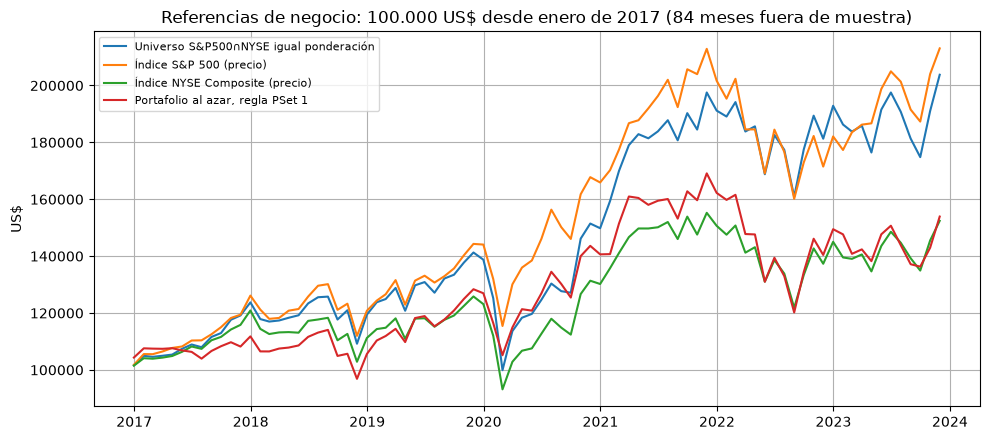

In [5]:
# Capital de 100.000 US$ invertido al inicio de 2017 con cada referencia (retorno neto de costos).
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, s in series.items():
    capital = 100_000 * (1 + s['neto']).cumprod()
    ax.plot(pd.PeriodIndex(s.index.astype(str), freq='M').to_timestamp() + pd.offsets.MonthEnd(1), capital, label=cortos[nombre])
ax.set_ylabel('US$'); ax.set_title('Referencias de negocio: 100.000 US$ desde enero de 2017 (84 meses fuera de muestra)')
ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(ROOT / 'docs/figuras/lineas_base_negocio.png', dpi=130, bbox_inches='tight'); plt.show()

In [6]:
# Vara que todo candidato debe superar (seccion 6): B1 en MAE y B5 en Sharpe neto.
vara = {'MAE de B1 (menor es mejor)': float(base_tecnica.set_index('modelo').loc['B1_media', 'mae_cv_media']) if REGISTRAR else np.nan,
        'MAE de B2 (menor es mejor)': float(base_tecnica.set_index('modelo').loc['B2_rw_cero', 'mae_cv_media']) if REGISTRAR else np.nan,
        'Sharpe neto de B5 (mayor es mejor)': float(tabla.loc['B5 universo S&P 500 ∩ NYSE, igual ponderación', 'sharpe_neto']),
        'Drawdown de B5 (referencia del error más costoso)': float(tabla.loc['B5 universo S&P 500 ∩ NYSE, igual ponderación', 'drawdown_max']),
        'Sharpe neto mediano de B4 (azar)': float(aleatorios.sharpe_neto.median())}
pd.Series(vara).round(4).to_frame('vara').to_csv(ROOT / 'docs/lineas_base.csv')
display(pd.Series(vara).round(4).to_frame('vara'))

,vara
MAE de B1 (menor es mejor),0.0641
MAE de B2 (menor es mejor),0.0647
Sharpe neto de B5 (mayor es mejor),0.5441
Drawdown de B5 (referencia del error más costoso),-0.2929
Sharpe neto mediano de B4 (azar),0.3443


**Lectura.**
- **Métrica técnica:** B1 y B2 tienen casi el mismo MAE (≈ 0,064). Predecir la media o predecir 0 es casi igual de
  bueno: el retorno del mes siguiente es casi ruido. Un candidato solo aporta si baja ese MAE.
- **Métrica de negocio:** B5 (todo el universo, igual ponderación) es la vara principal. Como ya vimos en el notebook
  03, un portafolio de 10 acciones con la regla del PSet 1 necesita elegir bien para superar a B5 después de costos.
  B4 dice cuánto se obtiene eligiendo al azar con la misma regla.
- **Índices:** el S&P 500 (Sharpe 0,63) queda **por encima** de B5 (0,54) aunque no incluye dividendos. En
  2017–2023 lo impulsaron las grandes tecnológicas de NASDAQ, que nuestro universo NYSE no puede comprar: es un costo
  de la restricción del universo, no del modelo, y se reporta como hallazgo. El NYSE Composite (0,34) queda por
  debajo, en parte por los dividendos y en parte porque incluye miles de acciones fuera del S&P 500. Ninguno de los
  dos es la vara del modelo.
- **B1 y B2 no tienen métrica de negocio:** una predicción constante no ordena acciones, y su referencia de negocio
  es B4.

**Criterio para la sección 6:** todo candidato debe tener un MAE de CV menor que el de B1 **y** un Sharpe neto mayor
que el de B5. El que no lo logre se documenta como hallazgo, como pide el PDF.

## 6. Candidatos (paso siguiente)

Se entrenan con `evaluar_candidatos(...)`, con la misma preparación, validación y métricas que B1 y B2. La celda
siguiente queda preparada y se ejecuta en el paso de la sección 6. La quinta familia (fundacional) y el LLM por
prompting necesitan su propio código y no se sustituyen por otro modelo de la misma familia.

In [7]:
# Ejecutar en la seccion 6 (candidatos M2-M5 del catalogo de src/experimentos.py):
# resultados = evaluar_candidatos(train, metadata, riesgo, metadata_dia,
#                                 nombres=['M2_random_forest', 'M3_lightgbm', 'M4_ridge', 'M5_mlp'])
# display(resultados)